In [5]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

Loading Dataset

In [6]:
dataset = pd.read_csv("C:\\Users\\patel\\OneDrive\\Coding Practice\\python practice\\Python Questions Practice\\MiniProjects\\super-market-sales-analysis-python\\Data\\supermarket_sales_eda.csv")
dataset.head(3)

,Invoice_ID,Branch,City,Customer_Type,Gender,Product_Line,Unit_Price,Quantity,Tax_5_Percent,Total,Date,Time,Payment,COGS,Gross_Income,Rating
0,INV-00001,A,Rajkot,Member,Male,Home and lifestyle,77.52,3.0,11.63,244.19,5/5/2025,19:10,Ewallet,232.56,11.63,8.6
1,INV-00002,A,Gandhinagar,Member,Female,Fashion accessories,23.68,2.0,2.37,49.73,4/28/2025,12:40,Credit card,47.36,2.37,7.0
2,INV-00003,C,Vadodara,Normal,Female,Health and beauty,51.25,3.0,7.69,161.44,3/21/2025,10:40,Credit card,153.75,7.69,6.6


In [7]:
dataset.shape

(1003, 16)

Checking And Handling Missing Values

In [8]:
dataset.isnull().sum()

Invoice_ID        0
Branch            0
City              0
Customer_Type     0
Gender            0
Product_Line      0
Unit_Price       10
Quantity         10
Tax_5_Percent     0
Total             0
Date              0
Time              0
Payment           0
COGS              0
Gross_Income      0
Rating           10
dtype: int64

In [9]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice_ID     1003 non-null   object 
 1   Branch         1003 non-null   object 
 2   City           1003 non-null   object 
 3   Customer_Type  1003 non-null   object 
 4   Gender         1003 non-null   object 
 5   Product_Line   1003 non-null   object 
 6   Unit_Price     993 non-null    float64
 7   Quantity       993 non-null    float64
 8   Tax_5_Percent  1003 non-null   float64
 9   Total          1003 non-null   float64
 10  Date           1003 non-null   object 
 11  Time           1003 non-null   object 
 12  Payment        1003 non-null   object 
 13  COGS           1003 non-null   float64
 14  Gross_Income   1003 non-null   float64
 15  Rating         993 non-null    float64
dtypes: float64(7), object(9)
memory usage: 125.5+ KB


In [10]:
# Handling Missing Values
columns = ["Invoice_ID","Branch","City","Customer_Type","Gender","Product_Line",
           "Unit_Price","Quantity","Tax_5_Percent","Total","Date","Time",
           "Payment","COGS","Gross_Income","Rating"]

for col in columns:
    if dataset[col].dtype == "float64":
        if col == "Quantity":
            dataset[col] = dataset[col].fillna(dataset[col].median())
        else:
            dataset[col] = dataset[col].fillna(dataset[col].mean())
    else:
        dataset[col] = dataset[col].fillna(dataset[col].mode()[0])

In [11]:
dataset.isnull().sum()

Invoice_ID       0
Branch           0
City             0
Customer_Type    0
Gender           0
Product_Line     0
Unit_Price       0
Quantity         0
Tax_5_Percent    0
Total            0
Date             0
Time             0
Payment          0
COGS             0
Gross_Income     0
Rating           0
dtype: int64

In [12]:
dataset.head(1)

,Invoice_ID,Branch,City,Customer_Type,Gender,Product_Line,Unit_Price,Quantity,Tax_5_Percent,Total,Date,Time,Payment,COGS,Gross_Income,Rating
0,INV-00001,A,Rajkot,Member,Male,Home and lifestyle,77.52,3.0,11.63,244.19,5/5/2025,19:10,Ewallet,232.56,11.63,8.6


Checking And Correcting Columns Data Type

In [13]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice_ID     1003 non-null   object 
 1   Branch         1003 non-null   object 
 2   City           1003 non-null   object 
 3   Customer_Type  1003 non-null   object 
 4   Gender         1003 non-null   object 
 5   Product_Line   1003 non-null   object 
 6   Unit_Price     1003 non-null   float64
 7   Quantity       1003 non-null   float64
 8   Tax_5_Percent  1003 non-null   float64
 9   Total          1003 non-null   float64
 10  Date           1003 non-null   object 
 11  Time           1003 non-null   object 
 12  Payment        1003 non-null   object 
 13  COGS           1003 non-null   float64
 14  Gross_Income   1003 non-null   float64
 15  Rating         1003 non-null   float64
dtypes: float64(7), object(9)
memory usage: 125.5+ KB


Finding And HAndling Outpliers IN Dataset

In [14]:
dataset.describe()

,Unit_Price,Quantity,Tax_5_Percent,Total,COGS,Gross_Income,Rating
count,1003.000000,1003.000000,1003.000000,1003.000000,1003.000000,1003.000000,1003.000000
mean,53.839859,5.459621,14.543450,305.407886,290.864437,14.543450,6.924169
std,25.533661,2.903146,10.806836,226.942254,216.135418,10.806836,1.261688
min,10.000000,1.000000,0.520000,10.900000,10.380000,0.520000,4.000000
25%,31.655000,3.000000,5.930000,124.550000,118.620000,5.930000,6.100000
50%,53.839859,5.000000,11.480000,240.980000,229.500000,11.480000,6.924169
75%,75.380000,8.000000,21.240000,446.105000,424.865000,21.240000,7.800000
max,99.960000,10.000000,49.660000,1042.960000,993.300000,49.660000,10.000000


In [15]:
list_of_columns = ["Unit_Price","Quantity","Tax_5_Percent","Total","COGS","Gross_Income","Rating"]

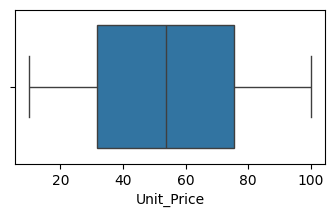

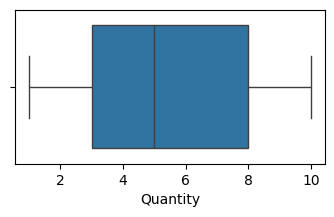

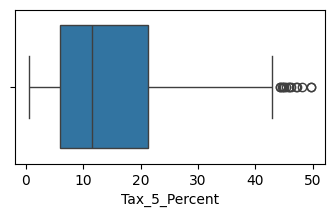

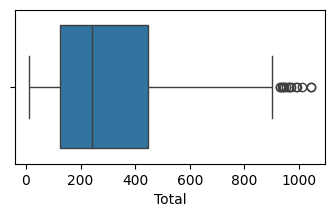

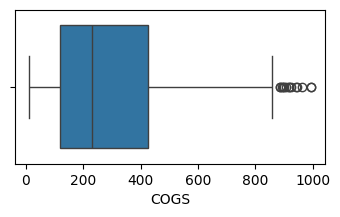

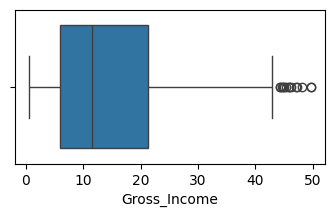

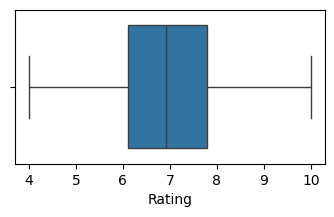

In [16]:
#Checking Outliers
for column in list_of_columns:
    plt.figure(figsize = (4,2))
    sns.boxplot(x=column,data = dataset)
    plt.show()

In [17]:
#Handling Outliers
for column in list_of_columns:
    Q1 = np.percentile(dataset[column],25)
    Q2 = np.percentile(dataset[column],50)
    Q3 = np.percentile(dataset[column],75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR
    dataset = dataset[(dataset[column] >= lower_bound) & (dataset[column] < upper_bound)]

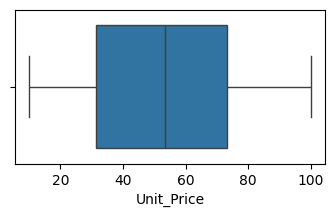

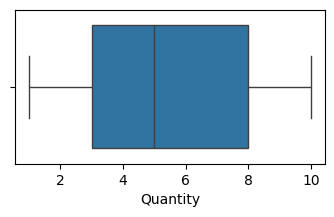

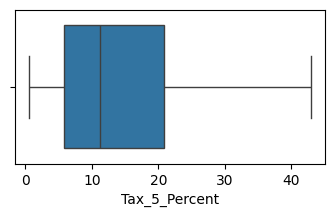

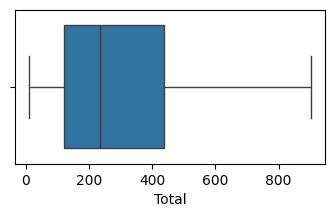

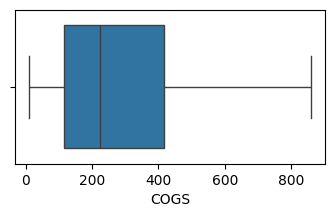

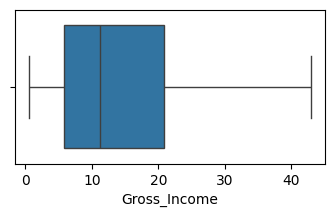

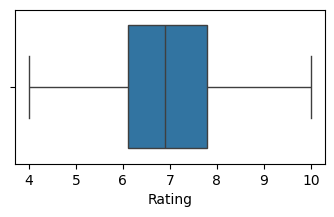

In [18]:
for column in list_of_columns:
    plt.figure(figsize = (4,2))
    sns.boxplot(x=column,data = dataset)
    plt.show()

In [19]:
dataset.shape

(989, 16)

Removing Duplication

In [20]:
#Checking duplicate data removed or not
dataset.duplicated().sum()

np.int64(3)

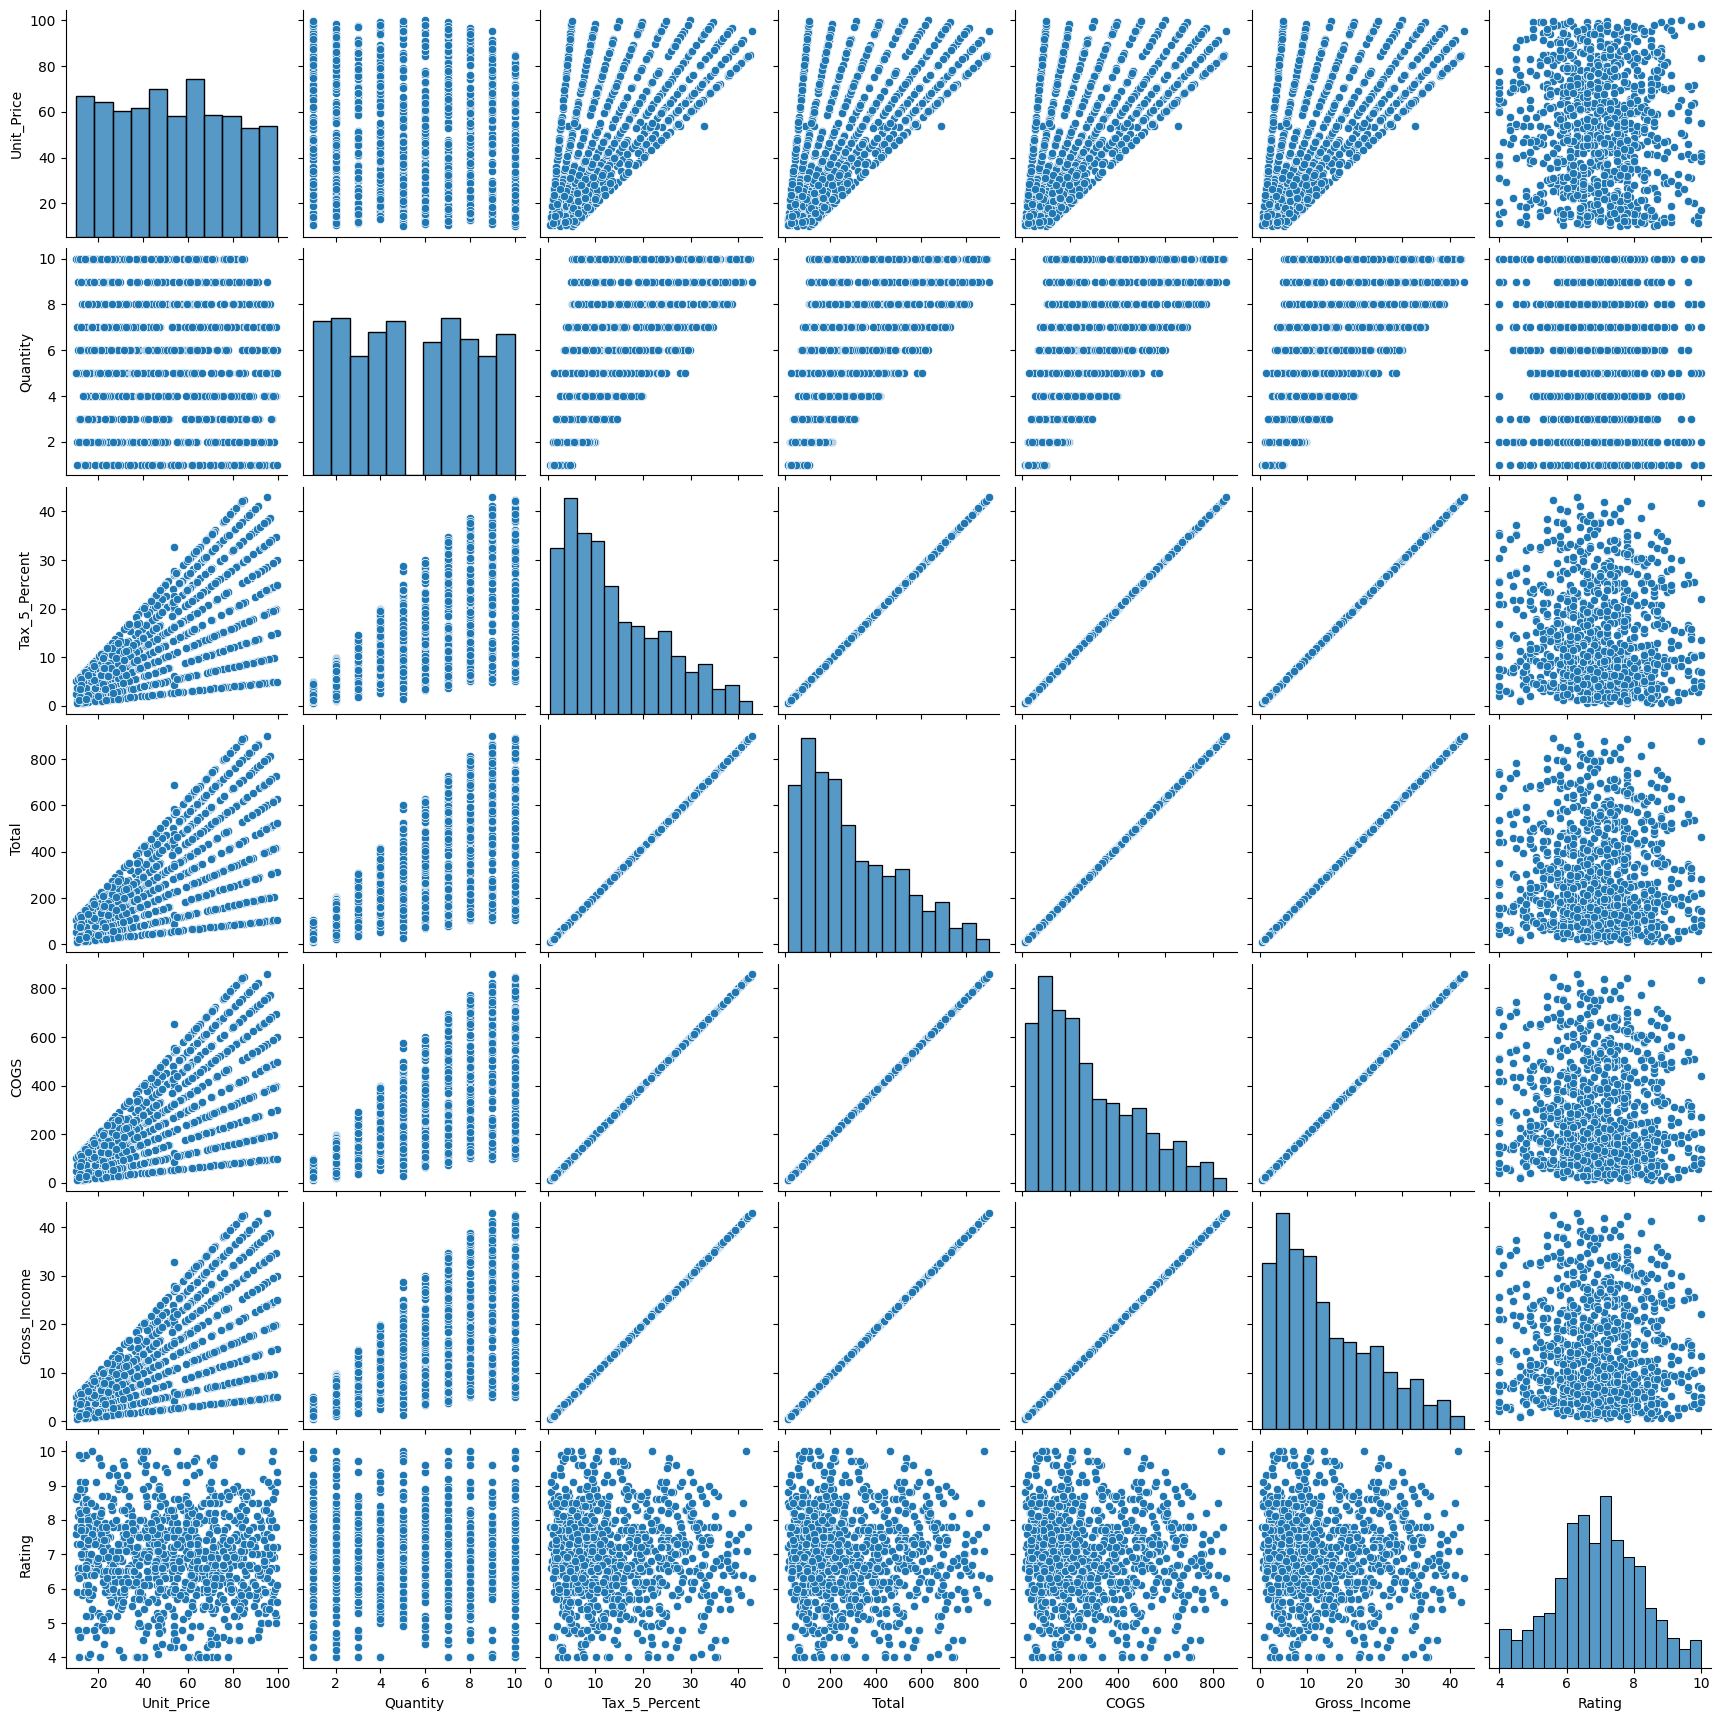

In [21]:
sns.pairplot(data=dataset)
plt.show()

In [22]:
dataset.head(3)

,Invoice_ID,Branch,City,Customer_Type,Gender,Product_Line,Unit_Price,Quantity,Tax_5_Percent,Total,Date,Time,Payment,COGS,Gross_Income,Rating
0,INV-00001,A,Rajkot,Member,Male,Home and lifestyle,77.52,3.0,11.63,244.19,5/5/2025,19:10,Ewallet,232.56,11.63,8.6
1,INV-00002,A,Gandhinagar,Member,Female,Fashion accessories,23.68,2.0,2.37,49.73,4/28/2025,12:40,Credit card,47.36,2.37,7.0
2,INV-00003,C,Vadodara,Normal,Female,Health and beauty,51.25,3.0,7.69,161.44,3/21/2025,10:40,Credit card,153.75,7.69,6.6


In [23]:
dataset_cov = dataset.select_dtypes(["float"]).cov()
dataset_corr = dataset.select_dtypes(["float"]).corr()

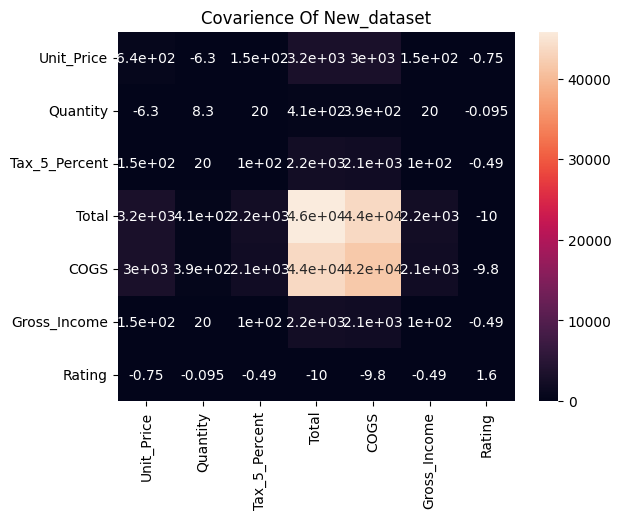

In [24]:
sns.heatmap(dataset_cov,annot=True)
plt.title("Covarience Of New_dataset")
plt.show()

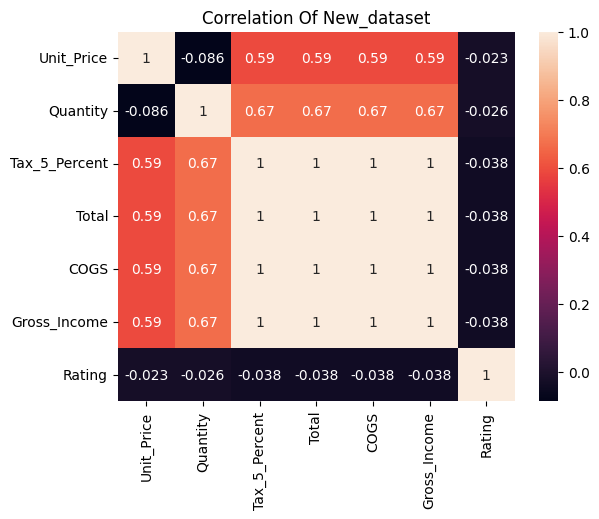

In [25]:
sns.heatmap(dataset_corr,annot=True)
plt.title("Correlation Of New_dataset")
plt.show()

Finding Trends

In [26]:
dataset["Date"] = pd.to_datetime(dataset["Date"])

In [27]:
monthly_sale = dataset.groupby(dataset["Date"].dt.month)["Total"].sum()

In [28]:
monthly_sale

Date
1    52722.62
2    41511.57
3    55224.36
4    34998.40
5    53841.11
6    54417.78
Name: Total, dtype: float64

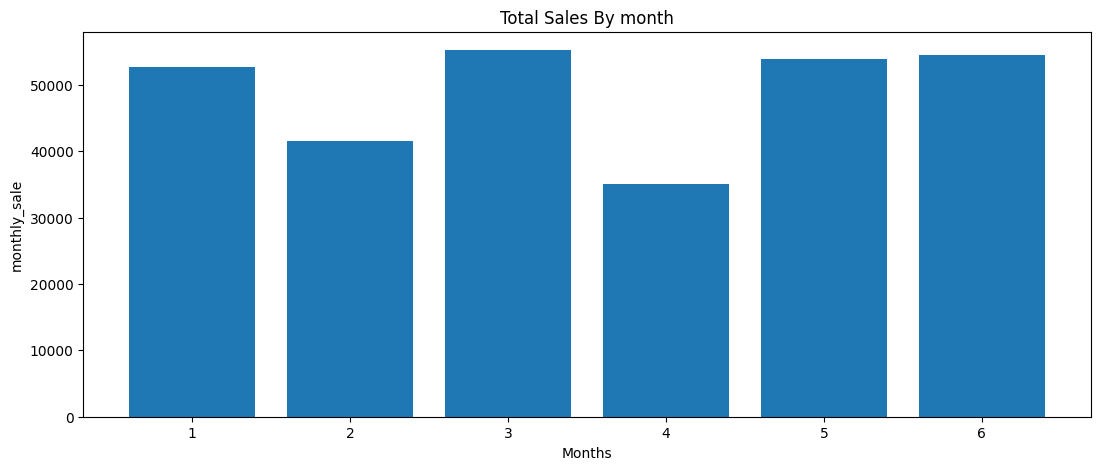

In [29]:
plt.figure(figsize=(13,5))
plt.bar(monthly_sale.index,monthly_sale.values)
plt.title("Total Sales By month")
plt.xlabel("Months")
plt.ylabel("monthly_sale")
plt.show()

In [30]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 989 entries, 0 to 1002
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice_ID     989 non-null    object        
 1   Branch         989 non-null    object        
 2   City           989 non-null    object        
 3   Customer_Type  989 non-null    object        
 4   Gender         989 non-null    object        
 5   Product_Line   989 non-null    object        
 6   Unit_Price     989 non-null    float64       
 7   Quantity       989 non-null    float64       
 8   Tax_5_Percent  989 non-null    float64       
 9   Total          989 non-null    float64       
 10  Date           989 non-null    datetime64[ns]
 11  Time           989 non-null    object        
 12  Payment        989 non-null    object        
 13  COGS           989 non-null    float64       
 14  Gross_Income   989 non-null    float64       
 15  Rating         989 non-null

Comparisions

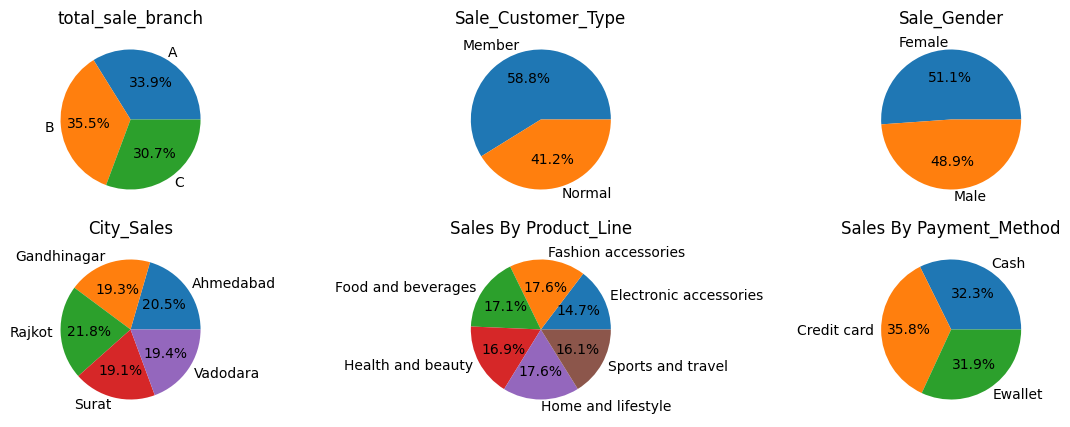

In [31]:
plt.figure(figsize=(15,5))
plt.subplot(2,3,1)
plt.title("total_sale_branch")
total_sale_branch = dataset.groupby("Branch")["Total"].sum()
plt.pie(total_sale_branch,labels=total_sale_branch.index,autopct = "%1.1f%%")

plt.subplot(2,3,2)
plt.title("Sale_Customer_Type")
Sale_Customer_Type = dataset.groupby("Customer_Type")["Total"].sum()
plt.pie(Sale_Customer_Type.values,labels=Sale_Customer_Type.index,autopct="%1.1f%%")


plt.subplot(2,3,3)
plt.title("Sale_Gender")
Sales_By_Gender = dataset.groupby("Gender")["Total"].sum()
plt.pie(Sales_By_Gender.values,labels=Sales_By_Gender.index,autopct="%1.1f%%")


plt.subplot(2,3,4)
plt.title("City_Sales")
Sales_By_City = dataset.groupby("City")["Total"].sum()
plt.pie(Sales_By_City.values,labels=Sales_By_City.index,autopct="%1.1f%%")


plt.subplot(2,3,5)
plt.title("Sales By Product_Line")
Sales_By_Product_Line = dataset.groupby("Product_Line")["Total"].sum()
plt.pie(Sales_By_Product_Line.values,labels=Sales_By_Product_Line.index,autopct="%1.1f%%")

plt.subplot(2,3,6)
plt.title("Sales By Payment_Method")
Sales_By_Payment_Method = dataset.groupby("Payment")["Total"].sum()
plt.pie(Sales_By_Payment_Method.values,labels=Sales_By_Payment_Method.index,autopct="%1.1f%%")
plt.show()

In [32]:
dataset.head(3)

,Invoice_ID,Branch,City,Customer_Type,Gender,Product_Line,Unit_Price,Quantity,Tax_5_Percent,Total,Date,Time,Payment,COGS,Gross_Income,Rating
0,INV-00001,A,Rajkot,Member,Male,Home and lifestyle,77.52,3.0,11.63,244.19,2025-05-05,19:10,Ewallet,232.56,11.63,8.6
1,INV-00002,A,Gandhinagar,Member,Female,Fashion accessories,23.68,2.0,2.37,49.73,2025-04-28,12:40,Credit card,47.36,2.37,7.0
2,INV-00003,C,Vadodara,Normal,Female,Health and beauty,51.25,3.0,7.69,161.44,2025-03-21,10:40,Credit card,153.75,7.69,6.6


Creating Model

In [33]:
#Finding The Median of Total
total_sale_median = dataset["Total"].median()
total_sale_median

np.float64(236.2)

In [34]:
#Creating Total Sales Class
list_sales_class = []
for i in dataset["Total"]:
    if i > total_sale_median:
        list_sales_class.append(1)
    else:
        list_sales_class.append(0)            

In [35]:
dataset["Total_Sale_Class"] = pd.DataFrame(list_sales_class)

In [36]:
dataset.head

<bound method NDFrame.head of      Invoice_ID Branch         City Customer_Type  Gender  \
0     INV-00001      A       Rajkot        Member    Male   
1     INV-00002      A  Gandhinagar        Member  Female   
2     INV-00003      C     Vadodara        Normal  Female   
3     INV-00004      B  Gandhinagar        Normal    Male   
4     INV-00005      A  Gandhinagar        Normal  Female   
...         ...    ...          ...           ...     ...   
998   INV-00999      B       Rajkot        Normal  Female   
999   INV-01000      B     Vadodara        Normal    Male   
1000  INV-00021      B        Surat        Normal    Male   
1001  INV-00101      B       Rajkot        Member  Female   
1002  INV-00251      B    Ahmedabad        Member  Female   

                Product_Line  Unit_Price  Quantity  Tax_5_Percent   Total  \
0         Home and lifestyle       77.52       3.0          11.63  244.19   
1        Fashion accessories       23.68       2.0           2.37   49.73   
2     

In [37]:
dataset["Total_Sale_Class"].value_counts()

Total_Sale_Class
1.0    489
0.0    486
Name: count, dtype: int64

In [38]:
#Removing Duplicated Data
dataset.dropna(inplace=True)

In [39]:
dataset = dataset.drop_duplicates()

In [40]:
dataset["Total_Sale_Class"] = dataset["Total_Sale_Class"].astype(int)

In [41]:
#Taking Input And Output Data
input_data = dataset[["Branch", "City", "Customer_Type", "Gender", "Product_Line", "Payment"]].copy()
input_data = pd.get_dummies(input_data, columns=["Branch", "City", "Customer_Type", "Gender", "Product_Line", "Payment"], drop_first=True)
output_data = dataset["Total_Sale_Class"]

In [42]:
input_data.head(3)

,Branch_B,Branch_C,City_Gandhinagar,City_Rajkot,City_Surat,City_Vadodara,Customer_Type_Normal,Gender_Male,Product_Line_Fashion accessories,Product_Line_Food and beverages,Product_Line_Health and beauty,Product_Line_Home and lifestyle,Product_Line_Sports and travel,Payment_Credit card,Payment_Ewallet
0,False,False,False,True,False,False,False,True,False,False,False,True,False,False,True
1,False,False,True,False,False,False,False,False,True,False,False,False,False,True,False
2,False,True,False,False,False,True,True,False,False,False,True,False,False,True,False


In [43]:
output_data.head(3)

0    1
1    0
2    0
Name: Total_Sale_Class, dtype: int64

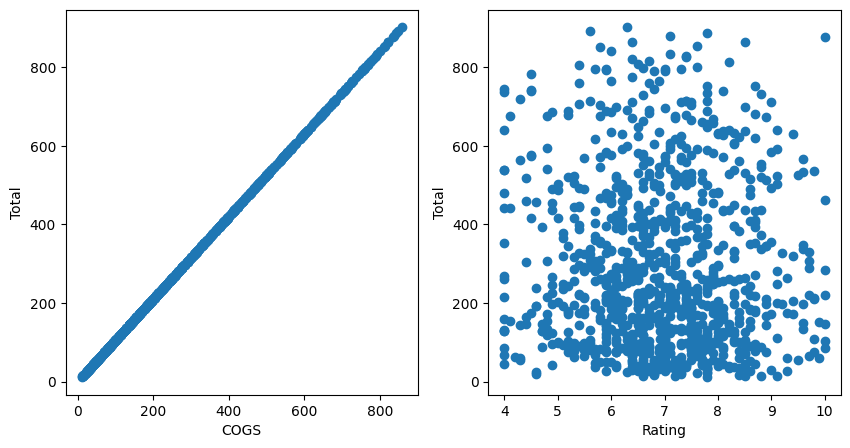

In [44]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.xlabel("COGS")
plt.ylabel("Total")
plt.scatter(dataset["COGS"],dataset["Total"])

plt.subplot(1,2,2)
plt.xlabel("Rating")
plt.ylabel("Total")
plt.scatter(dataset["Rating"],dataset["Total"])
plt.show()

Spliting Data Into Training and Testing set

In [45]:
from sklearn.model_selection import train_test_split

In [46]:
#Spliting Data into Training And Testing
x_train,x_test,y_train,y_test = train_test_split(input_data,output_data,test_size=0.2,random_state = 64)

Building LogisticRegression Model

In [47]:
#Training And Testing Model
from sklearn.linear_model import LogisticRegression

In [48]:
lr = LogisticRegression(random_state=64)

In [49]:
lr.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,64
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [50]:
print("Accuracy: ",lr.score(x_test,y_test)*100)

Accuracy:  55.8974358974359


In [51]:
y_pred_logistic_regression = lr.predict(x_test)

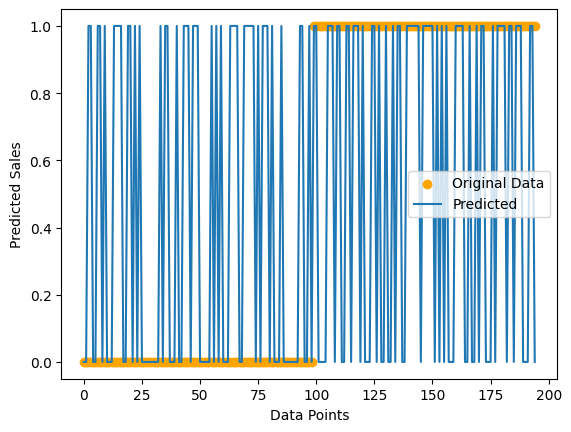

In [52]:
comparison = pd.DataFrame({"Actual":y_test.values,"Predicted":y_pred_logistic_regression}).sort_values("Actual")
plt.scatter(range(len(comparison["Actual"])),comparison["Actual"].values,label = "Original Data",color = "Orange")
plt.plot(comparison["Predicted"].values,label = "Predicted")
plt.xlabel("Data Points")
plt.ylabel("Predicted Sales")
plt.legend()
plt.show()

Building Decision Tree Classifier Model

In [53]:
from sklearn.tree import DecisionTreeClassifier

In [54]:
dtc = DecisionTreeClassifier(max_depth=5,random_state=64)

In [55]:
dtc.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,64
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [56]:
Accuracy = dtc.score(x_test,y_test)
print("Accuracy Decision Tree Classifier: ",Accuracy*100)

Accuracy Decision Tree Classifier:  56.41025641025641


In [57]:
y_prd_dtc = dtc.predict(x_test)

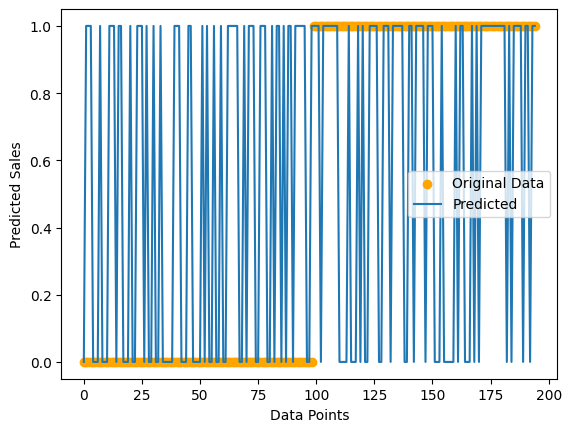

In [58]:
comparison = pd.DataFrame({"Actual":y_test.values,"Predicted":y_prd_dtc}).sort_values("Actual")
plt.scatter(range(len(comparison["Actual"])),comparison["Actual"].values,label = "Original Data",color = "Orange")
plt.plot(comparison["Predicted"].values,label = "Predicted")
plt.xlabel("Data Points")
plt.ylabel("Predicted Sales")
plt.legend()
plt.show()

Building Random Forest Classifier

In [59]:
from sklearn.ensemble import RandomForestClassifier

In [60]:
rfc = RandomForestClassifier(n_estimators=100,max_depth=5,random_state=64)

In [61]:
rfc.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [62]:
print("Accuracy(x_test,y_test)= ",rfc.score(x_test,y_test)*100,"Accuracy(x_train,y_train) = ",rfc.score(x_train,y_train)*100)

Accuracy(x_test,y_test)=  52.307692307692314 Accuracy(x_train,y_train) =  69.87179487179486


In [63]:
rfc_pred = rfc.predict(x_test)

Building KNN Model

In [64]:
from sklearn.neighbors import KNeighborsClassifier

In [65]:
knn = KNeighborsClassifier(n_neighbors=5)

In [66]:
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [67]:
knn_pred = knn.predict(x_test)
print(knn_pred)

[1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 0 0 0 0 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 0 0 0
 0 0 0 1 0 0 1 1 0 0 0 1 0 1 0 0 1 0 0 0 0 1 1 0 1 1 0 1 0 1 1 0 0 1 1 0 0
 1 0 1 0 1 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1 0 1 1 1 1 0 0 1 0 0 1 0 0 0 1 0
 0 0 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 1 0 1 0 1 0 1 0 0 0 1 1 0 1 1 1 1 1 0 0
 0 1 0 1 1 0 1 0 1 0 0 0 1 1 1 1 0 1 0 0 1 0 1 0 1 1 0 1 1 0 1 1 1 0 1 0 1
 0 1 1 1 1 1 1 0 1 1]


In [68]:
print("Accuracy(x_test,y_test) = ",knn.score(x_test,y_test)*100,"Accuracy(x_train,y_train) = ",knn.score(x_train,y_train)*100)

Accuracy(x_test,y_test) =  52.307692307692314 Accuracy(x_train,y_train) =  70.25641025641025


Accuracy, Precision, Recall, F1-Score, Confusion Matrix

In [69]:
from sklearn.metrics import precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.model_selection import cross_val_score

In [70]:
lr_cm = confusion_matrix(y_test,y_pred_logistic_regression)
dtc_cm = confusion_matrix(y_test,y_prd_dtc)
rfc_cm = confusion_matrix(y_test,rfc_pred)
knn_cm = confusion_matrix(y_test,knn_pred)

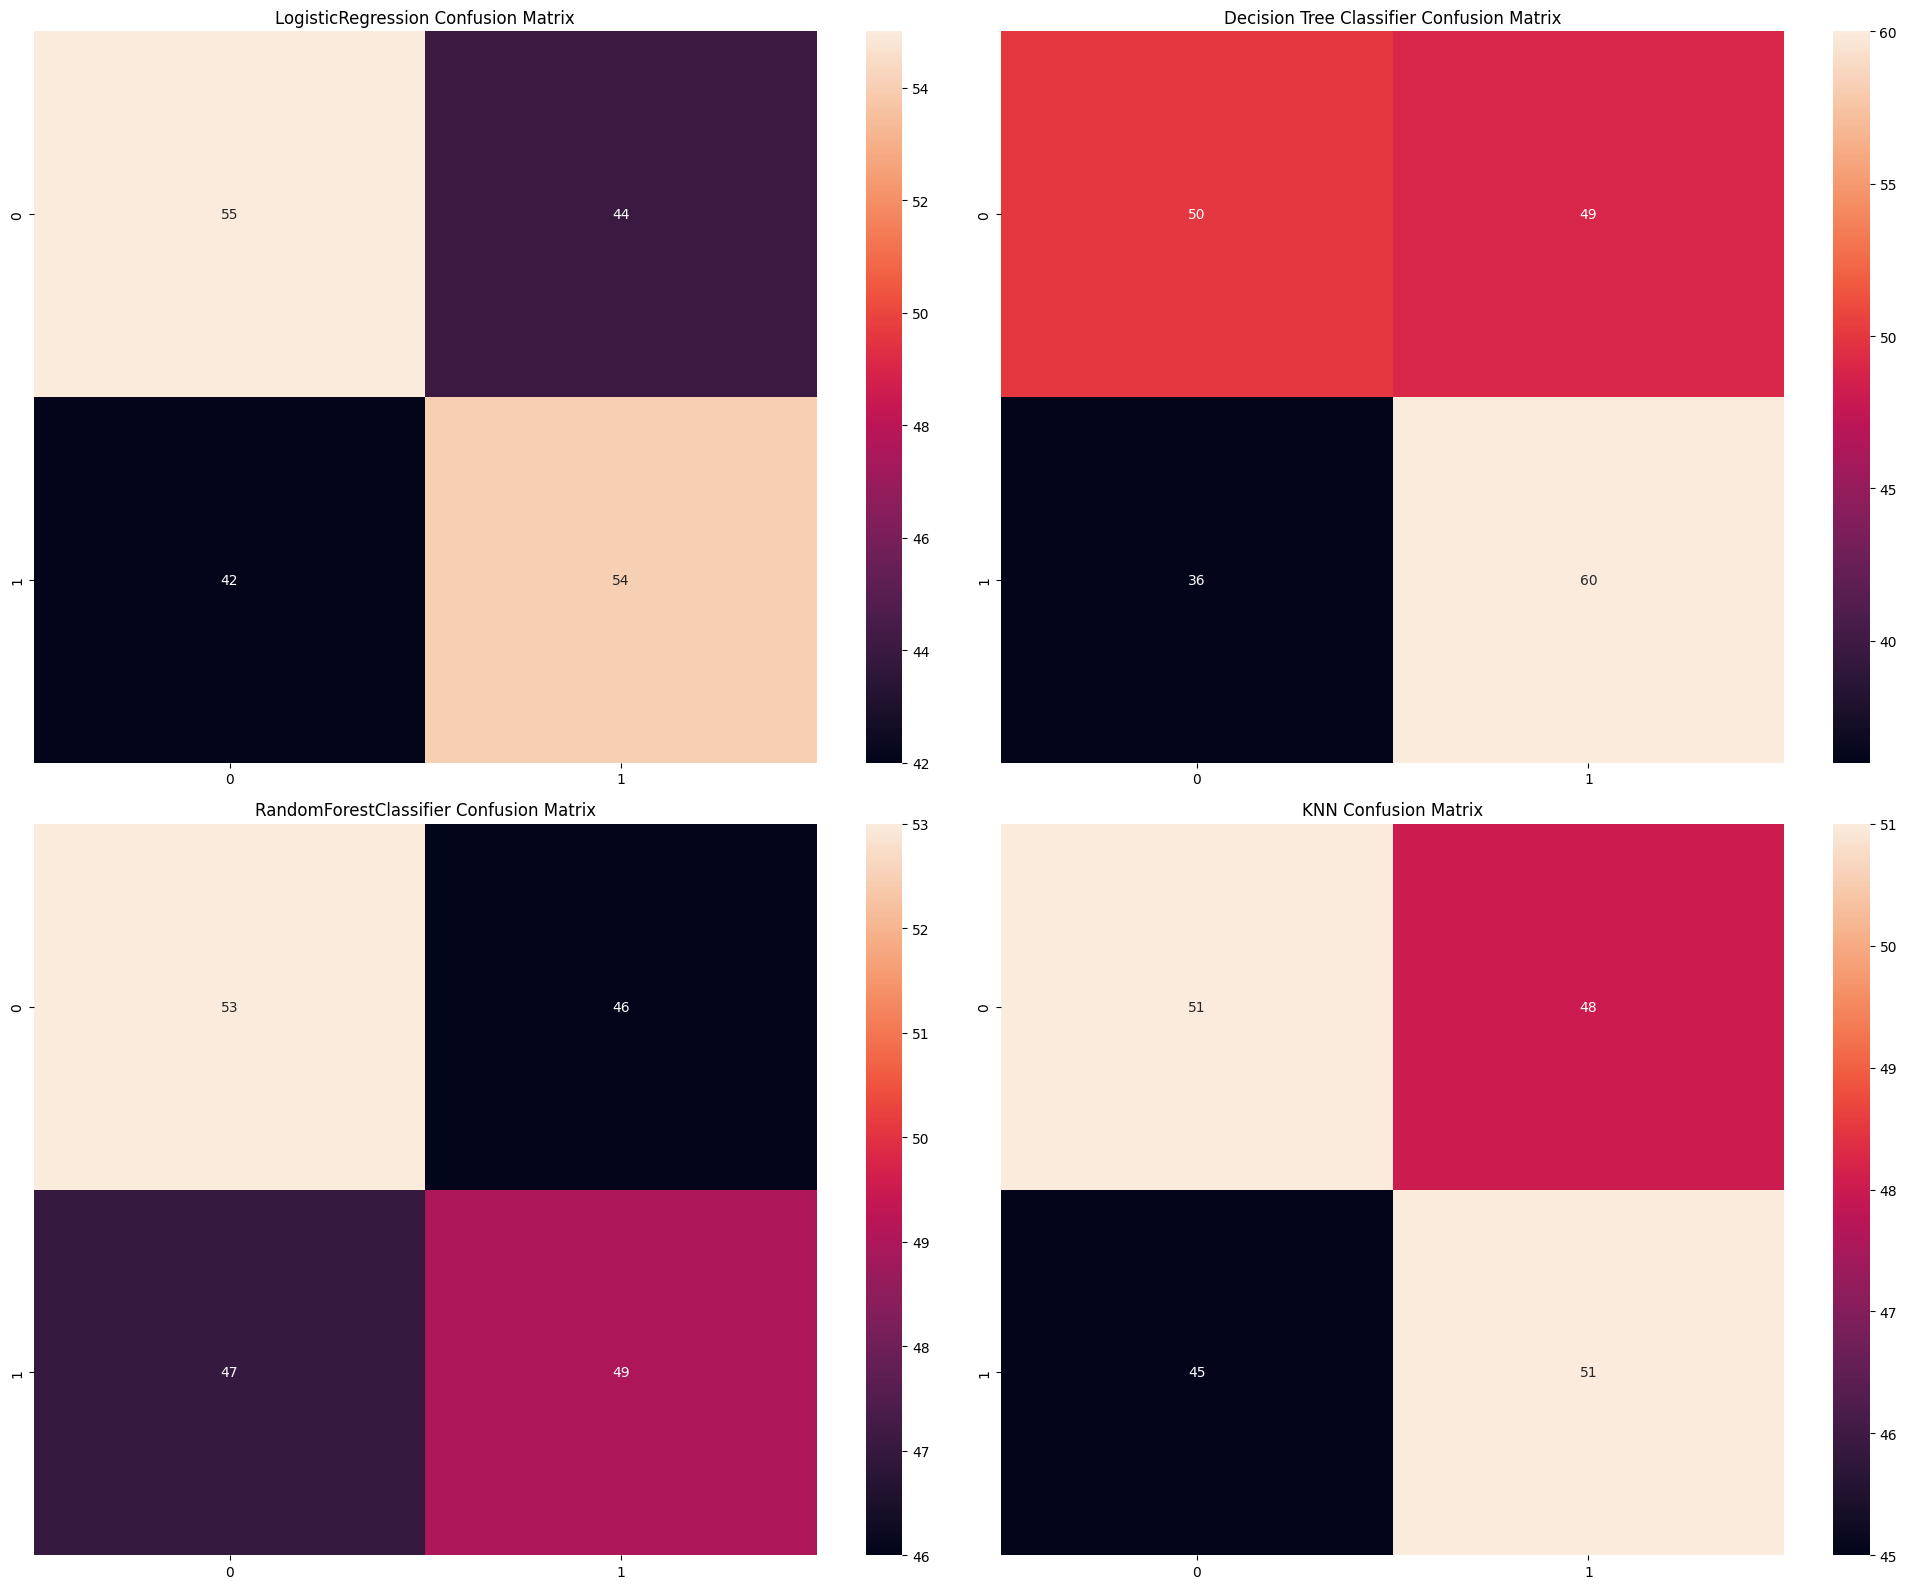

In [71]:
plt.figure(figsize=(20,16))

plt.subplot(2,2,1)
plt.title("LogisticRegression Confusion Matrix")
sns.heatmap(data=lr_cm, annot=True)

plt.subplot(2,2,2)
plt.title("Decision Tree Classifier Confusion Matrix")
sns.heatmap(data=dtc_cm, annot=True)

plt.subplot(2,2,3)
plt.title("RandomForestClassifier Confusion Matrix")
sns.heatmap(data=rfc_cm, annot=True)

plt.subplot(2,2,4)
plt.title("KNN Confusion Matrix")
sns.heatmap(data=knn_cm, annot=True)

plt.tight_layout()
plt.show()

Finding accuracy_score,precision_score,recall_score,f1_score

In [72]:
print("Model Name = Logistic Regression")
#print("Accuracy Score = ",accuracy_score(y_test,y_pred_logistic_regression))
print("precision_score = ",precision_score(y_test,y_pred_logistic_regression)*100)
print("Recall Score = ",recall_score(y_test,y_pred_logistic_regression)*100)
print("F1 Score = ",f1_score(y_test,y_pred_logistic_regression)*100)
print("\n")
print("Model Name = Decision Tree Classifier")
#print("Accuracy Score = ",accuracy_score(y_test,y_pred_logistic_regression))
print("precision_score = ",precision_score(y_test,y_prd_dtc)*100)
print("Recall Score = ",recall_score(y_test,y_prd_dtc)*100)
print("F1 Score = ",f1_score(y_test,y_prd_dtc)*100)

print("\n")
print("Model Name = Random Forest Classifier")
#print("Accuracy Score = ",accuracy_score(y_test,y_pred_logistic_regression))
print("precision_score = ",precision_score(y_test,rfc_pred)*100)
print("Recall Score = ",recall_score(y_test,rfc_pred)*100)
print("F1 Score = ",f1_score(y_test,rfc_pred)*100)

print("\n")
print("Model Name = K Nearest Neighbour")
#print("Accuracy Score = ",accuracy_score(y_test,y_pred_logistic_regression))
print("precision_score = ",precision_score(y_test,knn_pred)*100)
print("Recall Score = ",recall_score(y_test,knn_pred)*100)
print("F1 Score = ",f1_score(y_test,knn_pred)*100)

Model Name = Logistic Regression
precision_score =  55.10204081632652
Recall Score =  56.25
F1 Score =  55.670103092783506


Model Name = Decision Tree Classifier
precision_score =  55.04587155963303
Recall Score =  62.5
F1 Score =  58.536585365853654


Model Name = Random Forest Classifier
precision_score =  51.578947368421055
Recall Score =  51.041666666666664
F1 Score =  51.30890052356021


Model Name = K Nearest Neighbour
precision_score =  51.515151515151516
Recall Score =  53.125
F1 Score =  52.307692307692314


Finding Cross Validation Score

In [73]:
from sklearn.model_selection import cross_val_score

In [74]:
cv_results = []
for name, model in [("Logistic Regression", lr), ("Decision Tree", dtc),
                     ("Random Forest", rfc), ("KNN", knn)]:
    scores = cross_val_score(model, input_data, output_data, cv=5, scoring="accuracy")
    print(f"{name}: {scores.mean()*100:.2f}% (+/- {scores.std()*100:.2f}%)")
    cv_results.append({
        "Model": name,
        "Mean Accuracy (%)": round(scores.mean()*100, 2),
        "Std Dev (%)": round(scores.std()*100, 2)
    })


Logistic Regression: 49.64% (+/- 3.82%)
Decision Tree: 49.44% (+/- 5.47%)
Random Forest: 50.77% (+/- 3.67%)
KNN: 51.90% (+/- 3.45%)


In [75]:
cv_table = pd.DataFrame(cv_results).sort_values("Mean Accuracy (%)", ascending=False)
cv_table

,Model,Mean Accuracy (%),Std Dev (%)
3,KNN,51.90,3.45
2,Random Forest,50.77,3.67
0,Logistic Regression,49.64,3.82
1,Decision Tree,49.44,5.47
